In [1]:
import xcs_code_stockpile as xcs
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
proposal_number = 101927227  # noqa
run = 107  # noqa

In [3]:
h5 = xcs.load_smalldata(run, proposal_number)
h5dict = xcs.H5Dictionary(
    stack='epix_6/ROI_area',
    i0=lambda h5: h5['diodeGon/channels'][..., 0],
    laser_on='evr/code_41',
    delay='scan/awg_delay_ns_delay',
    measured_voltage='ai/ch04'
)

In [4]:
metadata = xcs.create_metadata(h5, run, h5dict, roi=None, nan_policy='ignore')
valid = xcs.sensible_filter(metadata, 0.5, 99.5, 0.5, 99.5)

Didn't find the key delay...


In [5]:
rois = [
    (slice(145, 155), slice(128, 138))
]

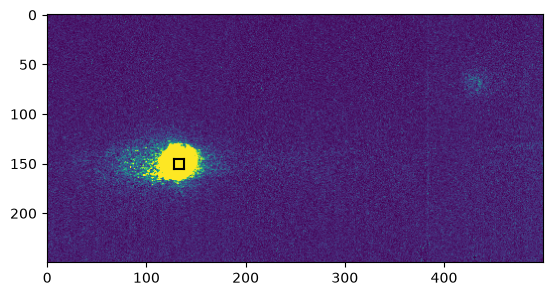

In [6]:
xcs.plot_detector_image(h5, h5dict, samplerate=100)
roi_colors = ['black', 'red', 'green', 'blue', 'purple', 'brown']
for i, roi in enumerate(rois):
    plt.plot([roi[1].start, roi[1].stop], [roi[0].start, roi[0].start], color=roi_colors[i])
    plt.plot([roi[1].start, roi[1].stop], [roi[0].stop, roi[0].stop], color=roi_colors[i])
    plt.plot([roi[1].start, roi[1].start], [roi[0].start, roi[0].stop], color=roi_colors[i])
    plt.plot([roi[1].stop, roi[1].stop], [roi[0].start, roi[0].stop], color=roi_colors[i])

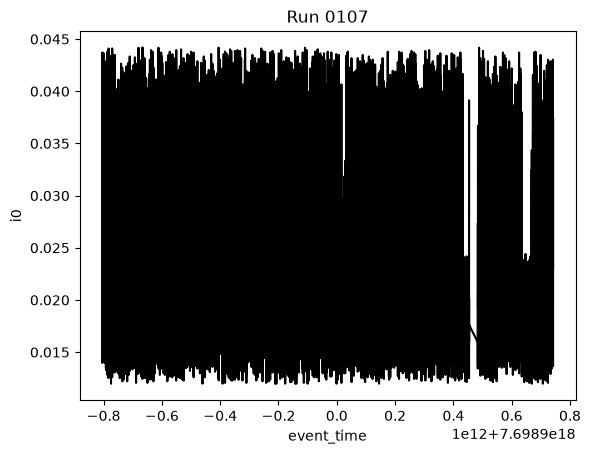

In [7]:
xcs.plot_i0_vs_time(metadata, valid).show()

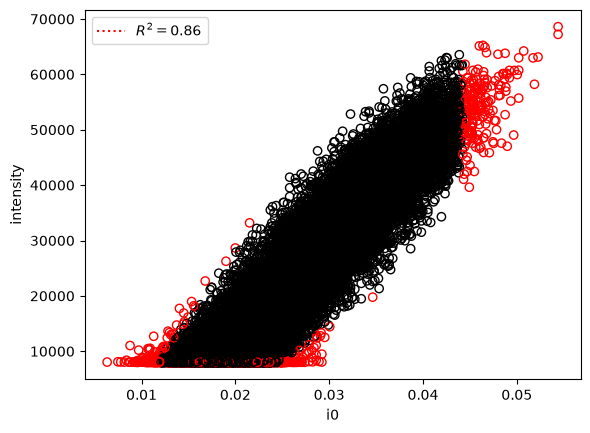

In [8]:
xcs.plot_intensity_vs_i0(metadata, valid).show()

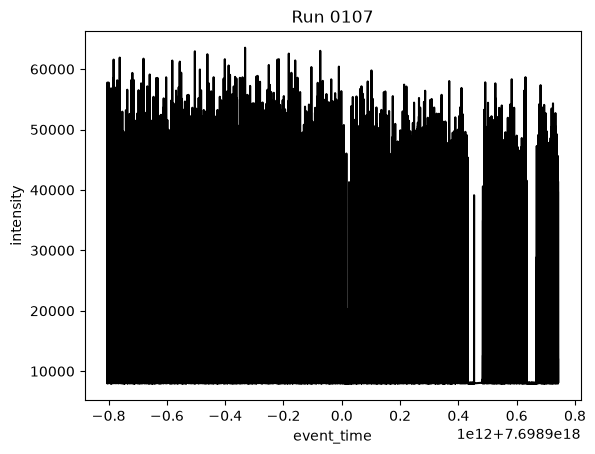

In [9]:
xcs.plot_intensity_vs_time(metadata, valid).show()

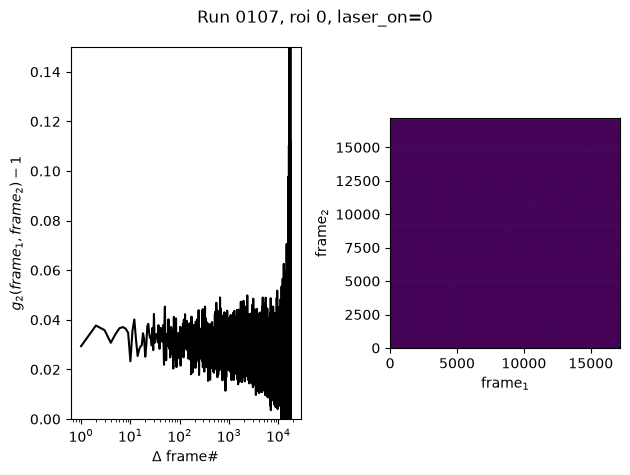

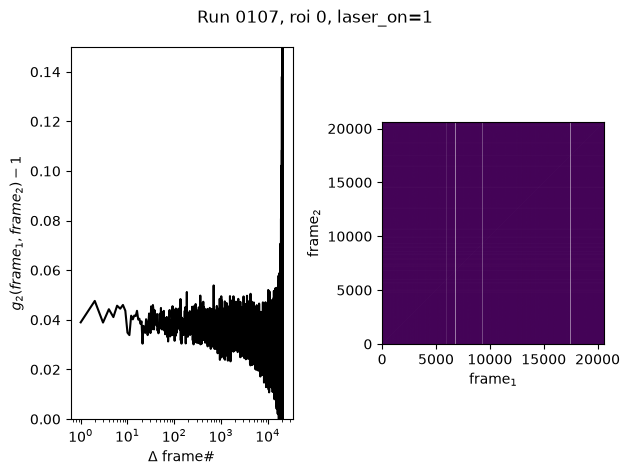

In [11]:
for shot_type in range(metadata['laser_on'].nunique()):
    shot_type_metadata = metadata[metadata['laser_on'] == shot_type]
    shot_type_valid = valid[metadata['laser_on'] == shot_type]
    for j, (roi, color) in enumerate(zip(rois, roi_colors)):
        st_corr, st_twotime = xcs.calc_static_correlation(h5, h5dict, shot_type_metadata, shot_type_valid, roi=roi, denominator_type='nanmean', ret_twotime=True)
        fig, axs = plt.subplots(1, 2)
        axs[0].semilogx(st_corr, label=f'roi {j}', color=color)
        axs[1].imshow(st_twotime, origin='lower')
        axs[0].set_xlabel(r'$\Delta$ frame#')
        axs[0].set_ylabel(r'$g_2(frame_1, frame_2) - 1$')
        axs[1].set_xlabel(r'frame$_1$')
        axs[1].set_ylabel(r'frame$_2$')
        axs[0].set_ylim(0.0, 0.15)
        fig.suptitle(f'Run {run:04d}, roi {j}, laser_on={shot_type}')
        fig.tight_layout()
        fig.show()